In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/shivanshranjan4213/baseline-resnet-efficient-vgg/efficientnet_b3_full_best.pth
/kaggle/input/notebooks/shivanshranjan4213/baseline-resnet-efficient-vgg/__results__.html
/kaggle/input/notebooks/shivanshranjan4213/baseline-resnet-efficient-vgg/vgg16_full_best.pth
/kaggle/input/notebooks/shivanshranjan4213/baseline-resnet-efficient-vgg/__notebook__.ipynb
/kaggle/input/notebooks/shivanshranjan4213/baseline-resnet-efficient-vgg/__output__.json
/kaggle/input/notebooks/shivanshranjan4213/baseline-resnet-efficient-vgg/baseline_results_full_finetune.csv
/kaggle/input/notebooks/shivanshranjan4213/baseline-resnet-efficient-vgg/resnet50_full_best.pth
/kaggle/input/notebooks/shivanshranjan4213/baseline-resnet-efficient-vgg/custom.css
/kaggle/input/notebooks/bisusiddharth/edda-attention-fusion-notebook/__results__.html
/kaggle/input/notebooks/bisusiddharth/edda-attention-fusion-notebook/__huggingface_repos__.json
/kaggle/input/notebooks/bisusiddharth/edda-attention-fusion-not

In [2]:
# ===== CELL 1: baseline CNNs -> predictions on YOUR split_D123.csv test set =====
import os, glob, re
import numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T, models
from PIL import Image, ImageFile
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
ImageFile.LOAD_TRUNCATED_IMAGES = True

SIZE = 224                                   # image size the baselines were trained with (change only if the check below is far off)
OUT = "/kaggle/working/baselines"
CLASSES = ["Normal", "DR", "Glaucoma", "AMD", "Myopia"]
DISEASE_CLASSES = CLASSES[1:]
FILE_COL, SOURCE_COL, PATH_COL, SPLIT_COL = "filename", "source_dataset", "image_path", "split"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGE_SLUGS = {"D1": "edda-d1-odir5k-clean", "D2": "edda-d2-mured-clean", "D3": "edda-d3-rfmid-clean"}


def find_file(name, root="/kaggle/input"):
    for d, _, fs in os.walk(root):
        if name in fs:
            return os.path.join(d, name)


def find_input_dir(slug, base="/kaggle/input", max_depth=4):
    bd = base.rstrip("/").count("/")
    for root, dirs, _ in os.walk(base):
        if os.path.basename(root) == slug:
            return root
        if root.count("/") - bd >= max_depth:
            dirs[:] = []
    raise FileNotFoundError(f"Dataset '{slug}' not found under {base}. Add it as input.")


CK = {"VGG16": "vgg16_full_best.pth", "ResNet50": "resnet50_full_best.pth", "EfficientNet-B3": "efficientnet_b3_full_best.pth"}
for k in CK:
    p = find_file(CK[k]); assert p, f"{CK[k]} not found: add the baseline notebook's output as an input"
    CK[k] = p

# ---------- YOUR split (the one the baselines were trained on): split_D123.csv
SPLIT_CSV = find_file("split_D123.csv"); assert SPLIT_CSV, "split_D123.csv not found: add your edda_train_val_test_split notebook as input"
print("using split file:", SPLIT_CSV)
df_all = pd.read_csv(SPLIT_CSV)
print("columns:", list(df_all.columns)); print(df_all[SPLIT_COL].value_counts().to_dict())
df_all[CLASSES] = df_all[CLASSES].fillna(0).astype(int).clip(0, 1)

# which source dataset does each image come from?
def src_of(row):
    for v in (str(row.get(SOURCE_COL, "")), str(row.get(FILE_COL, "")), str(row.get(PATH_COL, ""))):
        m = re.search(r"(?<![A-Za-z0-9])[dD]([123])(?![0-9])", v)
        if m:
            return "D" + m.group(1)
    return "?"
df_all["src"] = df_all.apply(src_of, axis=1)
print("images per source:", df_all["src"].value_counts().to_dict())

_idx = None
def image_index():
    global _idx
    if _idx is None:
        _idx = {}
        for slug in IMAGE_SLUGS.values():
            for root, _, files in os.walk(find_input_dir(slug)):
                for f in files:
                    _idx.setdefault(f, os.path.join(root, f))
    return _idx

if PATH_COL in df_all.columns:
    ok = df_all[PATH_COL].map(lambda p: isinstance(p, str) and os.path.exists(p))
else:
    ok = pd.Series(False, index=df_all.index); df_all[PATH_COL] = None
if not ok.all():
    df_all.loc[~ok, PATH_COL] = df_all.loc[~ok, FILE_COL].map(image_index())
df_all = df_all.dropna(subset=[PATH_COL]).reset_index(drop=True)
df_all["img_path"] = df_all[PATH_COL]
df_all[SOURCE_COL] = df_all["src"]

val_df = df_all[df_all[SPLIT_COL] == "val"].reset_index(drop=True)
test_all = df_all[df_all[SPLIT_COL] == "test"].reset_index(drop=True)
TEST_SETS = {"D123_in_domain": test_all}
for s in IMAGE_SLUGS:
    TEST_SETS[f"{s}_test"] = test_all[test_all["src"] == s].reset_index(drop=True)
print("test sizes:", {k: len(v) for k, v in TEST_SETS.items()}, "| val:", len(val_df))
assert all(len(v) > 0 for v in TEST_SETS.values()), "a test set is empty: paste me the 'columns' and 'images per source' lines above"

# ---------- model construction from the checkpoint itself
def strip(obj):
    sd = obj
    if isinstance(obj, dict):
        for k in ("state_dict", "model_state_dict", "model"):
            if k in obj and isinstance(obj[k], dict):
                sd = obj[k]; break
    return {k.replace("module.", "", 1): v for k, v in sd.items()}


def nav(m, path):
    for p in path:
        m = m[int(p)] if p.isdigit() else getattr(m, p)
    return m


def build(name, sd):
    heads = [k for k, v in sd.items() if k.endswith(".weight") and v.ndim == 2 and v.shape[0] == 5]
    assert heads, f"{name}: no 5-class output layer found in the checkpoint"
    hk = heads[-1]; in_f = sd[hk].shape[1]; path = hk[:-len(".weight")].split(".")
    if "conv_stem.weight" in sd or "pre_logits.fc1.weight" in sd:          # timm-style checkpoint
        import timm
        arch = {"VGG16": "vgg16", "ResNet50": "resnet50", "EfficientNet-B3": "efficientnet_b3"}[name]
        return timm.create_model(arch, pretrained=False, num_classes=5)
    m = {"VGG16": models.vgg16, "ResNet50": models.resnet50, "EfficientNet-B3": models.efficientnet_b3}[name](weights=None)
    parent = nav(m, path[:-1]); last = path[-1]; new = nn.Linear(in_f, 5)
    if last.isdigit() and isinstance(parent, nn.Sequential):
        parent[int(last)] = new
    elif last.isdigit():                                                     # e.g. fc = Sequential(Dropout, Linear)
        seq = nn.Sequential(*[nn.Identity() for _ in range(int(last))], new)
        setattr(nav(m, path[:-2]), path[-2], seq)
    else:
        setattr(parent, last, new)
    return m


tf = T.Compose([T.Resize((SIZE, SIZE)), T.ToTensor(), T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])


class DS(Dataset):
    def __init__(self, df):
        self.p, self.y = df["img_path"].values, df[CLASSES].values.astype("float32")
    def __len__(self):
        return len(self.p)
    def __getitem__(self, i):
        return tf(Image.open(self.p[i]).convert("RGB")), torch.from_numpy(self.y[i])


@torch.no_grad()
def predict(model, df):
    model.eval(); out = []
    for x, _ in DataLoader(DS(df), batch_size=64, shuffle=False, num_workers=2):
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            out.append(torch.sigmoid(model(x.to(DEVICE)).float()).cpu())
    return torch.cat(out).numpy()


def metrics(Y, Pr, th):
    rows = {}
    for j, c in enumerate(CLASSES):
        yt, yp = Y[:, j], Pr[:, j]
        rows[c] = {"AUC": roc_auc_score(yt, yp) if 0 < yt.sum() < len(yt) else np.nan,
                   "AP": average_precision_score(yt, yp) if yt.sum() > 0 else np.nan,
                   "F1": f1_score(yt, (yp >= th[j]).astype(int), zero_division=0), "support": int(yt.sum())}
    t = pd.DataFrame(rows).T.astype(float)
    for nm, cols in [("macro", CLASSES), ("macro_disease", DISEASE_CLASSES)]:
        t.loc[nm] = [t.loc[cols, "AUC"].mean(), t.loc[cols, "AP"].mean(), t.loc[cols, "F1"].mean(), t.loc[cols, "support"].sum()]
    return t.round(4)


def tune(Y, Pr):
    grid = np.linspace(0.05, 0.95, 91)
    return np.array([grid[np.argmax([f1_score(Y[:, j], (Pr[:, j] >= t).astype(int), zero_division=0) for t in grid])] for j in range(5)])


rep = find_file("baseline_results_full_finetune.csv")
reported = pd.read_csv(rep).set_index("Model")["Macro-F1"].to_dict() if rep else {}
Yv = val_df[CLASSES].values
for name, path in CK.items():
    sd = strip(torch.load(path, map_location="cpu", weights_only=False))
    model = build(name, sd)
    try:
        model.load_state_dict(sd, strict=True)
    except Exception as e:
        print(f"\n{name}: LOAD FAILED -> send me this message:\n", str(e)[:1500]); raise
    model.to(DEVICE)
    th = tune(Yv, predict(model, val_df))
    res, preds = [], []
    for ts, df in TEST_SETS.items():
        Pr = predict(model, df); m = metrics(df[CLASSES].values, Pr, th)
        res.append(m.assign(test_set=ts, **{"class": m.index}))
        p = df[[FILE_COL, SOURCE_COL] + CLASSES].copy()
        for j, c in enumerate(CLASSES):
            p[f"prob_{c}"] = Pr[:, j]
        preds.append(p.assign(test_set=ts))
    d = f"{OUT}/{name}"; os.makedirs(d, exist_ok=True)
    pd.concat(res)[["test_set", "class", "AUC", "AP", "F1", "support"]].to_csv(f"{d}/test_metrics.csv", index=False)
    pd.concat(preds).to_csv(f"{d}/test_predictions.csv", index=False)
    pooled = metrics(TEST_SETS["D123_in_domain"][CLASSES].values, predict(model, TEST_SETS["D123_in_domain"]), th)
    key = {"VGG16": "vgg16", "ResNet50": "resnet50", "EfficientNet-B3": "efficientnet_b3"}[name]
    print(f"{name}: OK | pooled macro-AUROC {pooled.loc['macro','AUC']:.4f} | macro-F1 here {pooled.loc['macro','F1']:.4f} "
          f"| macro-F1 in your baseline csv {reported.get(key, float('nan')):.4f}")
print("\nSaved to", OUT)


using split file: /kaggle/input/notebooks/bisusiddharth/edda-train-val-test-split/splits/split_D123.csv
columns: ['filename', 'source_dataset', 'image_path', 'Normal', 'DR', 'Glaucoma', 'AMD', 'Myopia', 'split']
{'train': 5881, 'val': 1260, 'test': 1260}
images per source: {'D1': 5261, 'D3': 1923, 'D2': 1217}
test sizes: {'D123_in_domain': 1260, 'D1_test': 764, 'D2_test': 191, 'D3_test': 305} | val: 1260
VGG16: OK | pooled macro-AUROC 0.8997 | macro-F1 here 0.7388 | macro-F1 in your baseline csv 0.7980
ResNet50: OK | pooled macro-AUROC 0.9293 | macro-F1 here 0.7663 | macro-F1 in your baseline csv 0.8038
EfficientNet-B3: OK | pooled macro-AUROC 0.9270 | macro-F1 here 0.7481 | macro-F1 in your baseline csv 0.7850

Saved to /kaggle/working/baselines


run folders: {'VGG16': '/kaggle/working/baselines/VGG16', 'ResNet50': '/kaggle/working/baselines/ResNet50', 'EfficientNet-B3': '/kaggle/working/baselines/EfficientNet-B3'}

=== TABLE 1: macro metrics by test set ===


macro_AUROC                                     \
test_set        Pooled (D123) D1 · ODIR-5K D2 · MuReD D3 · RFMiD   
model                                                              
VGG16                  0.8997       0.8342     0.9419     0.9527   
ResNet50               0.9293       0.8805     0.9609     0.9761   
EfficientNet-B3        0.9270       0.8742     0.9732     0.9710   

                     macro_AP                                     \
test_set        Pooled (D123) D1 · ODIR-5K D2 · MuReD D3 · RFMiD   
model                                                              
VGG16                  0.7992       0.6702     0.8815     0.8920   
ResNet50               0.8457       0.7303     0.9277     0.9338   
EfficientNet-B3        0.8317       0.6851     0.9368     0.9257   

                     macro_F1                                     
test_set        Pooled (D123) D1 · ODIR-5K D2 · MuReD D3 · RFMiD  
model                                                             
VGG16                  0.7388       0.6537     0.8071     0.8189  
ResNet50               0.7663       0.6641     0.8660     0.8511  
EfficientNet-B3        0.7481       0.6542     0.8298     0.8385


=== TABLE 2: per-class metrics, pooled test set ===


AUROC                               AP                           \
model      VGG16 ResNet50 EfficientNet-B3   VGG16 ResNet50 EfficientNet-B3   
class                                                                        
Normal    0.8554   0.8793          0.8667  0.7997   0.8421          0.8356   
DR        0.8621   0.8800          0.8745  0.8006   0.8190          0.8079   
Glaucoma  0.8939   0.9519          0.9454  0.6985   0.8127          0.7726   
AMD       0.9018   0.9414          0.9519  0.7708   0.8119          0.7848   
Myopia    0.9853   0.9937          0.9967  0.9265   0.9428          0.9574   

              F1                           
model      VGG16 ResNet50 EfficientNet-B3  
class                                      
Normal    0.7842   0.8110          0.7894  
DR        0.6807   0.7156          0.6806  
Glaucoma  0.6436   0.6920          0.6795  
AMD       0.7226   0.7303          0.7250  
Myopia    0.8630   0.8824          0.8662


=== TABLE 3: paired bootstrap of macro-AUROC differences (95% CI) ===


,test_set,comparison,AUROC_diff,CI_low,CI_high,clear difference (CI excludes 0)
0,Pooled (D123),ResNet50 - VGG16,0.0295,0.0167,0.0441,True
1,Pooled (D123),EfficientNet-B3 - VGG16,0.0273,0.0138,0.0416,True
2,Pooled (D123),EfficientNet-B3 - ResNet50,-0.0022,-0.0130,0.0080,False
3,D1 · ODIR-5K,ResNet50 - VGG16,0.0463,0.0218,0.0749,True
4,D1 · ODIR-5K,EfficientNet-B3 - VGG16,0.0401,0.0126,0.0676,True
5,D1 · ODIR-5K,EfficientNet-B3 - ResNet50,-0.0062,-0.0256,0.0127,False
6,D2 · MuReD,ResNet50 - VGG16,0.0190,-0.0067,0.0481,False
7,D2 · MuReD,EfficientNet-B3 - VGG16,0.0314,0.0112,0.0566,True
8,D2 · MuReD,EfficientNet-B3 - ResNet50,0.0123,-0.0067,0.0363,False
9,D3 · RFMiD,ResNet50 - VGG16,0.0234,0.0079,0.0418,True


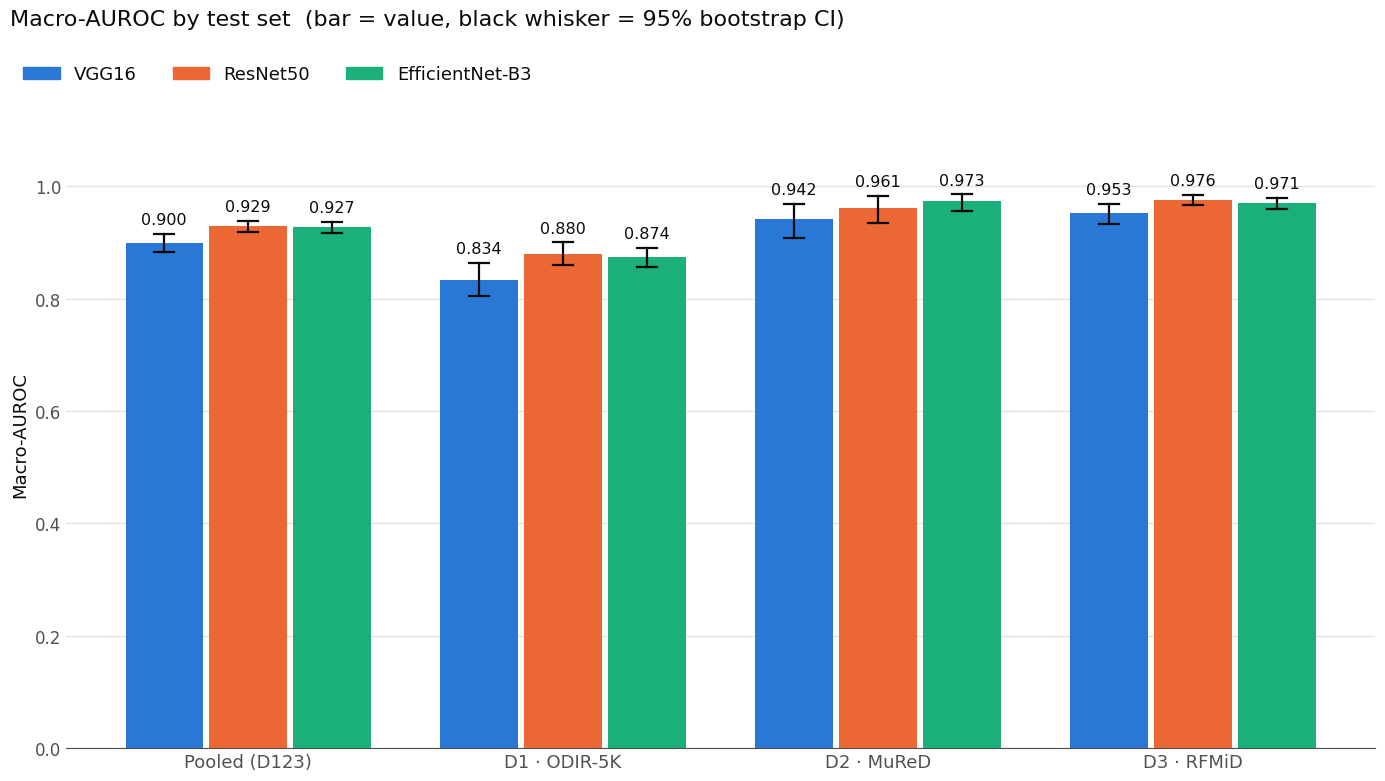

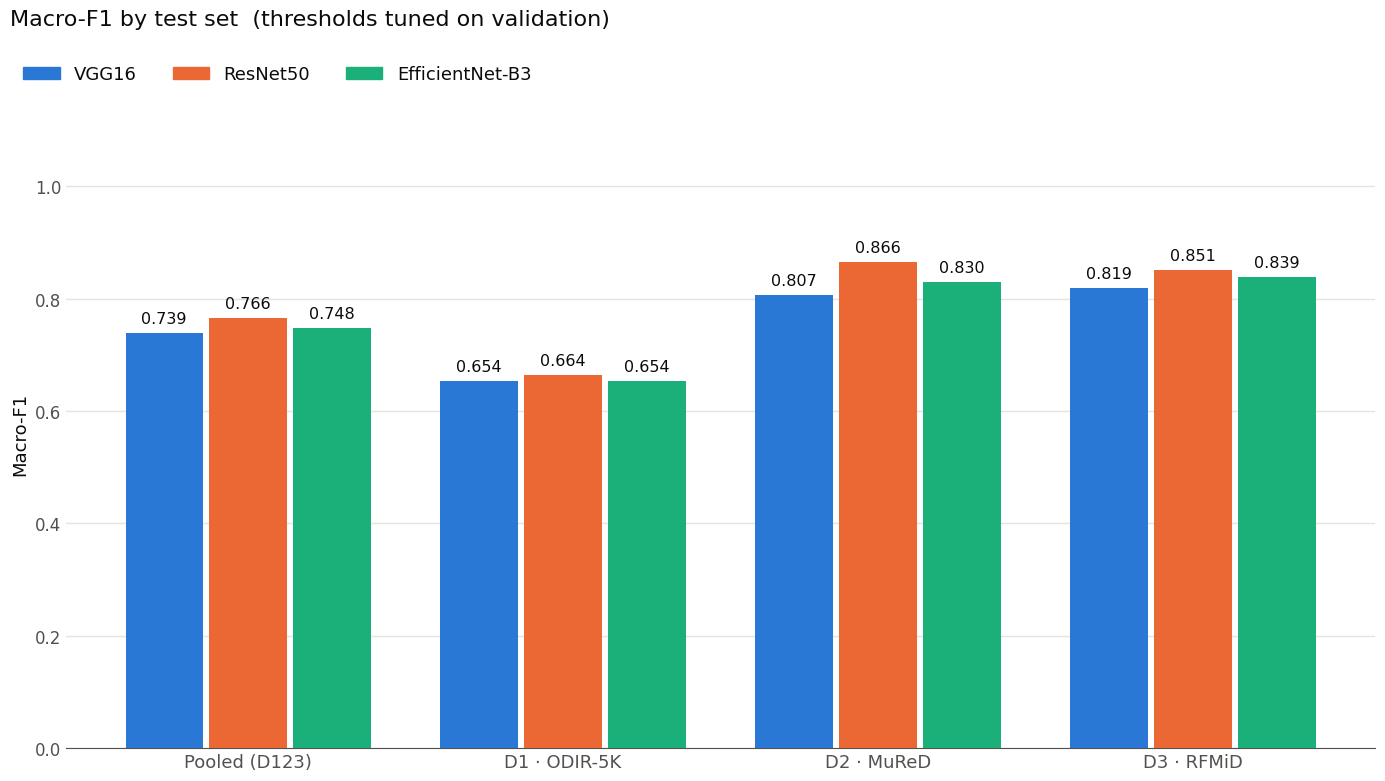

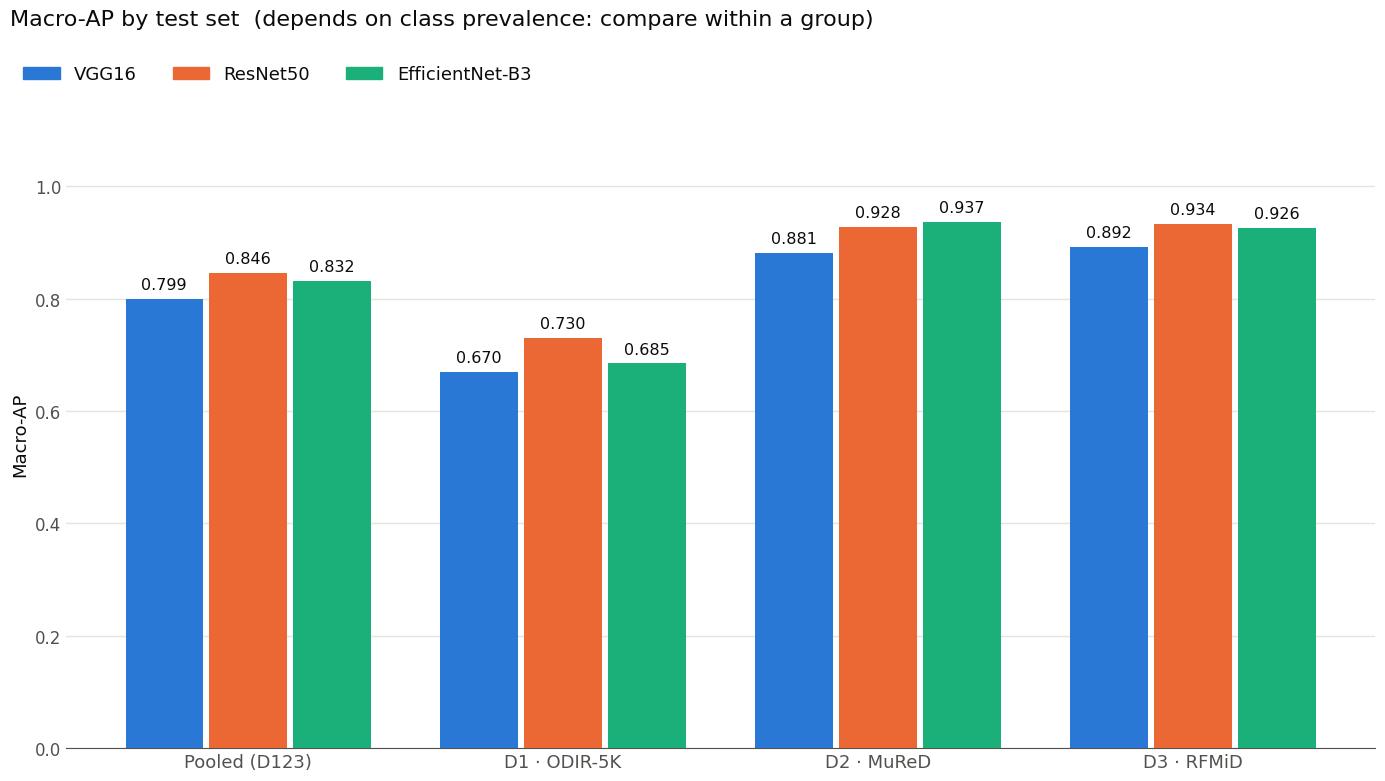

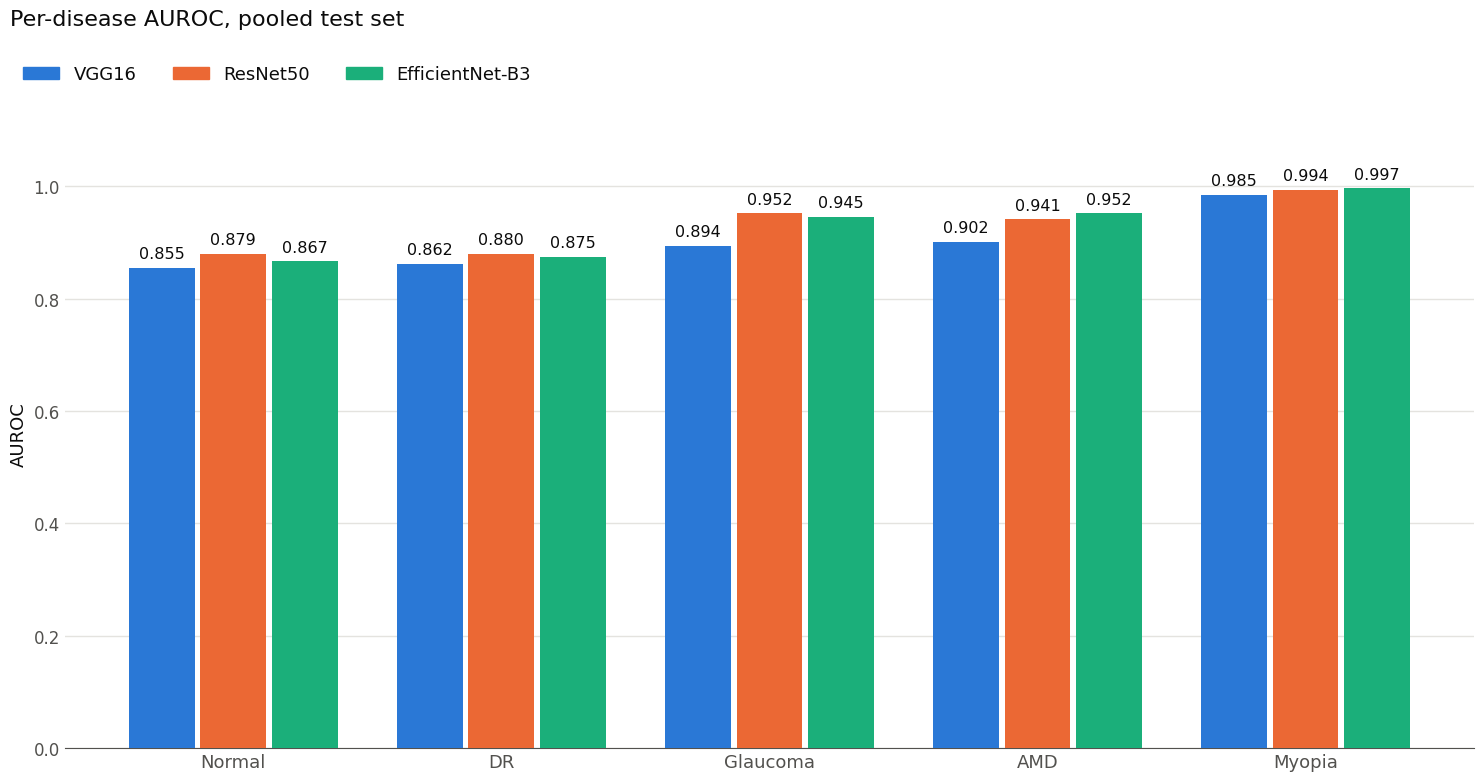

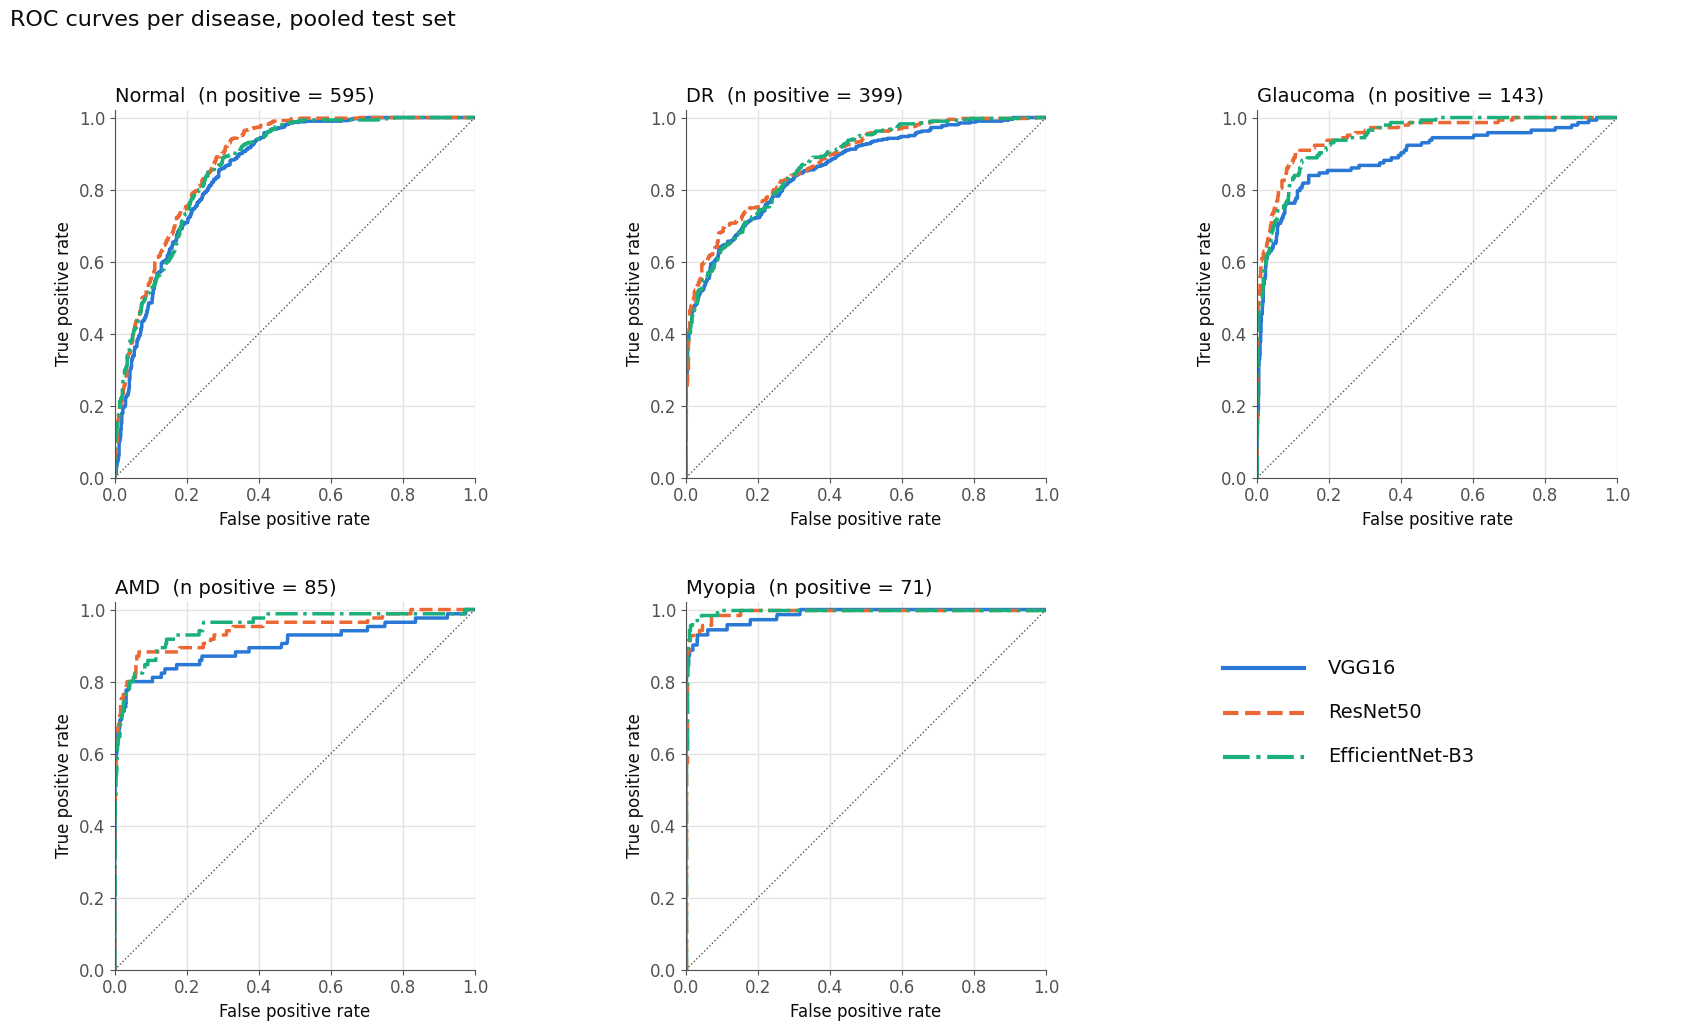

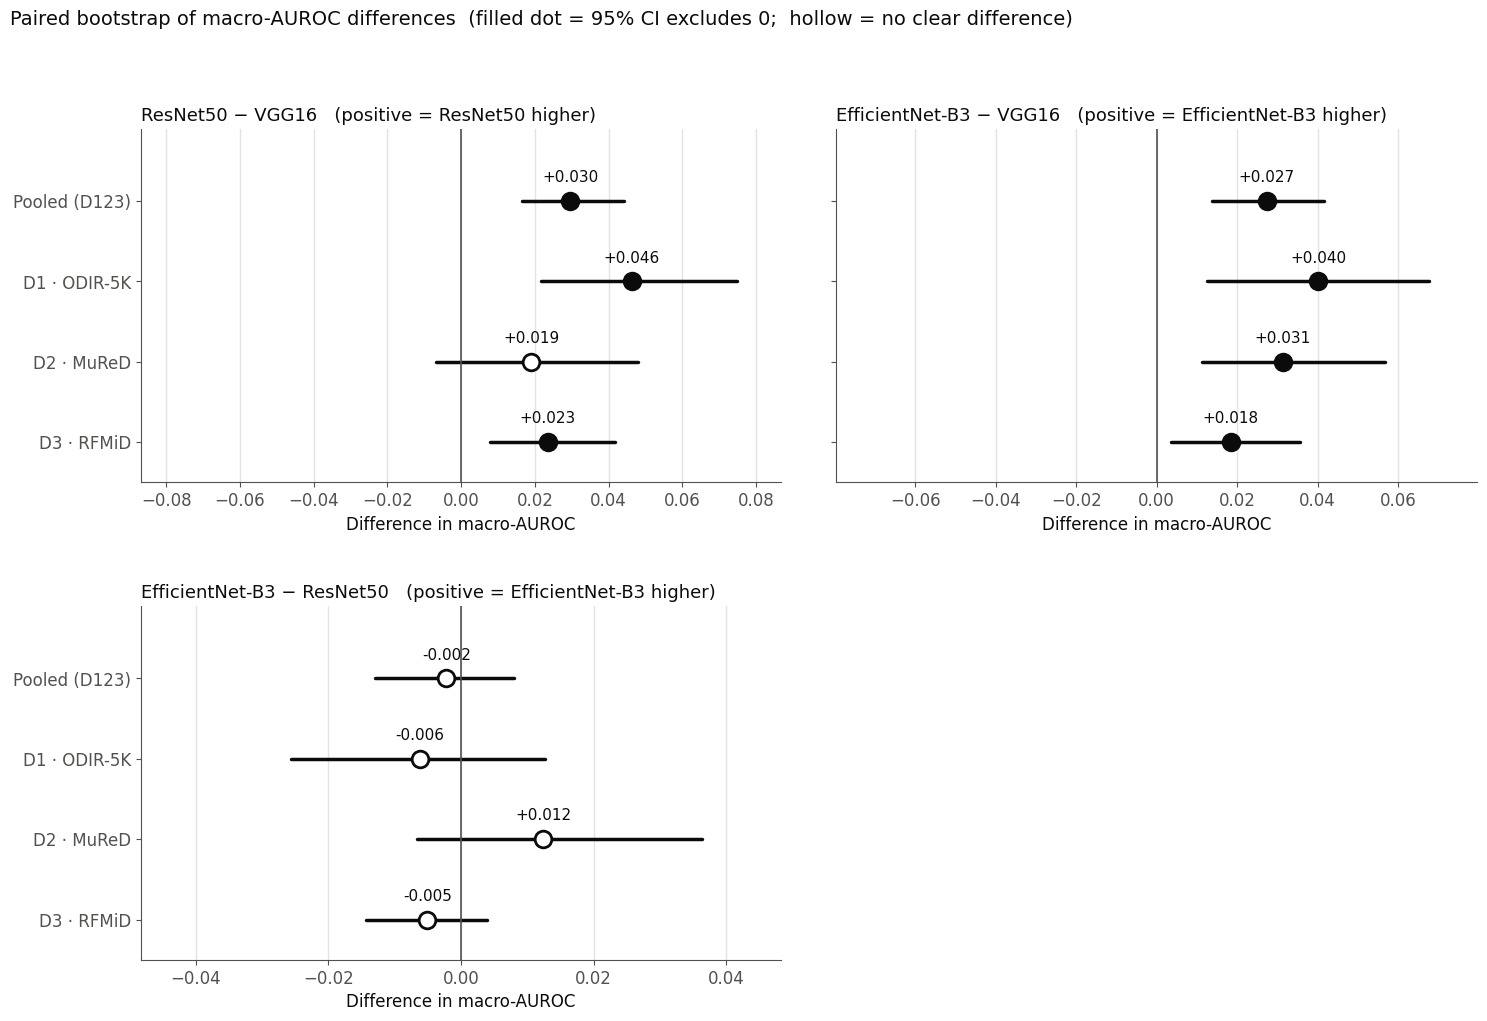


Saved to /kaggle/working/comparison_baselines : ['fig1_macro_auroc.png', 'fig2_macro_f1.png', 'fig3_macro_ap.png', 'fig4_per_class_auroc.png', 'fig5_roc_per_disease.png', 'fig6_paired_differences.png', 'table1_macro_by_set.csv', 'table2_per_class_pooled.csv', 'table3_paired_bootstrap.csv']


In [3]:
# ============================================================
# Comparison of 3 models within one group (baselines OR transformer-based)
# Each run folder must contain test_metrics.csv and test_predictions.csv
# ============================================================
import os, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

# ---------- EDIT ONLY THIS LINE ----------
GROUP = "baselines"          # run once with "baselines", then again with "transformers"
N_BOOT = 1000
# -----------------------------------------

def find_run(folder_name, root):
    """folder (exact name) that contains both result files"""
    for d, _, fs in os.walk(root):
        if os.path.basename(d) == folder_name and "test_predictions.csv" in fs and "test_metrics.csv" in fs:
            return d
    raise FileNotFoundError(f"No folder named '{folder_name}' with test_metrics.csv + test_predictions.csv under {root}. "
                            f"Add that notebook's output as an input (and make sure it was saved with Save & Run All).")

def find_run_kw(keyword, root):
    """any folder whose path contains the keyword and that holds both result files"""
    for d, _, fs in os.walk(root):
        if keyword in d.lower() and "test_predictions.csv" in fs and "test_metrics.csv" in fs:
            return d
    raise FileNotFoundError(f"No folder with '{keyword}' in its path and both result files under {root}. Upload the RETFound results as a dataset named retfound-d123-results and add it as input.")

ALL_RUNS = {
    "baselines": {
        "VGG16":           "/kaggle/working/baselines/VGG16",
        "ResNet50":        "/kaggle/working/baselines/ResNet50",
        "EfficientNet-B3": "/kaggle/working/baselines/EfficientNet-B3",
    },
    "transformers": {
        "RETFound alone":  lambda: find_run_kw("retfound", "/kaggle/input"),
        "Concat":          lambda: find_run("Fusion_D123", "/kaggle/input"),
        "Attention":       lambda: find_run("AttnFusion_D123", "/kaggle/input"),
    },
}
RUNS = {k: (v() if callable(v) else v) for k, v in ALL_RUNS[GROUP].items()}
print("run folders:", RUNS)
OUT = f"/kaggle/working/comparison_{GROUP}"

CLASSES = ["Normal", "DR", "Glaucoma", "AMD", "Myopia"]
SETS = ["D123_in_domain", "D1_test", "D2_test", "D3_test"]
LABEL = {"D123_in_domain": "Pooled (D123)", "D1_test": "D1 · ODIR-5K", "D2_test": "D2 · MuReD", "D3_test": "D3 · RFMiD"}
NAMES = list(RUNS)
COLOR = dict(zip(NAMES, ["#2a78d6", "#eb6834", "#1baf7a"]))   # validated, fixed per model
MARK = dict(zip(NAMES, ["o", "s", "^"]))
STYLE = dict(zip(NAMES, ["-", "--", "-."]))
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.facecolor": "white", "axes.facecolor": "white"})
try:
    from IPython.display import display
except Exception:
    display = print

# ---------- load + align on identical images
M, P = {}, {}
for n, d in RUNS.items():
    for f in ("test_metrics.csv", "test_predictions.csv"):
        assert os.path.exists(os.path.join(d, f)), f"missing {f} in {d} (model: {n})"
    M[n] = pd.read_csv(os.path.join(d, "test_metrics.csv"))
    P[n] = pd.read_csv(os.path.join(d, "test_predictions.csv"))

A = {}
for s in SETS:
    keys = None
    for n in NAMES:
        k = set(P[n].loc[P[n].test_set == s, "filename"])
        keys = k if keys is None else keys & k
    sizes = {n: int((P[n].test_set == s).sum()) for n in NAMES}
    if any(v != len(keys) for v in sizes.values()):
        print(f"WARNING {s}: models do not share the same images {sizes} -> using the {len(keys)} common ones")
    ref, probs = None, {}
    for n in NAMES:
        g = P[n][(P[n].test_set == s) & P[n].filename.isin(keys)].sort_values("filename").reset_index(drop=True)
        if ref is None:
            ref = g[CLASSES].values
        else:
            assert (g[CLASSES].values == ref).all(), f"labels differ between models in {s}"
        probs[n] = g[[f"prob_{c}" for c in CLASSES]].values
    A[s] = (ref, probs)


def macro_auc(Y, Pr):
    v = [roc_auc_score(Y[:, j], Pr[:, j]) for j in range(5) if 0 < Y[:, j].sum() < len(Y)]
    return np.mean(v) if len(v) == 5 else np.nan


# ---------- tables
rows = []
for n in NAMES:
    for s in SETS:
        r = M[n][(M[n].test_set == s) & (M[n]["class"] == "macro")].iloc[0]
        rows.append({"model": n, "test_set": s, "macro_AUROC": r.AUC, "macro_AP": r.AP, "macro_F1": r.F1})
T = pd.DataFrame(rows)
cols = [(k, LABEL[s]) for k in ["macro_AUROC", "macro_AP", "macro_F1"] for s in SETS]
tab = T.assign(test_set=T.test_set.map(LABEL)).pivot(index="model", columns="test_set",
        values=["macro_AUROC", "macro_AP", "macro_F1"]).reindex(NAMES).reindex(columns=cols)
print("\n=== TABLE 1: macro metrics by test set ===")
display(tab.round(4)); tab.round(4).to_csv(f"{OUT}/table1_macro_by_set.csv")

pc = []
for n in NAMES:
    for c in CLASSES:
        r = M[n][(M[n].test_set == "D123_in_domain") & (M[n]["class"] == c)].iloc[0]
        pc.append({"model": n, "class": c, "AUROC": r.AUC, "AP": r.AP, "F1": r.F1})
PC = pd.DataFrame(pc)
t2 = PC.pivot(index="class", columns="model", values=["AUROC", "AP", "F1"]).reindex(CLASSES)
t2 = t2.reindex(columns=[(k, n) for k in ["AUROC", "AP", "F1"] for n in NAMES])
print("\n=== TABLE 2: per-class metrics, pooled test set ===")
display(t2.round(4)); t2.round(4).to_csv(f"{OUT}/table2_per_class_pooled.csv")

# ---------- all pairs within the group
Yp, prp = A["D123_in_domain"]
PAIRS = [(b, a) for a, b in itertools.combinations(NAMES, 2)]   # (first, second): positive difference = first higher

# ---------- bootstrap, same resample for every model
rng = np.random.default_rng(42)
CI, DIFF = {}, {}
for s in SETS:
    Y, pr = A[s]; n_img = len(Y)
    boot = {n: [] for n in NAMES}
    for _ in range(N_BOOT):
        i = rng.integers(0, n_img, n_img)
        v = {n: macro_auc(Y[i], pr[n][i]) for n in NAMES}
        if not any(np.isnan(x) for x in v.values()):
            for n in NAMES:
                boot[n].append(v[n])
    for n in NAMES:
        CI[(s, n)] = (macro_auc(Y, pr[n]), *np.percentile(boot[n], [2.5, 97.5]))
    for a, b in PAIRS:
        d = np.array(boot[a]) - np.array(boot[b])
        DIFF[(s, a, b)] = (macro_auc(Y, pr[a]) - macro_auc(Y, pr[b]), *np.percentile(d, [2.5, 97.5]))
dt = pd.DataFrame([{"test_set": LABEL[s], "comparison": f"{a} - {b}", "AUROC_diff": v[0], "CI_low": v[1], "CI_high": v[2],
                    "clear difference (CI excludes 0)": not (v[1] <= 0 <= v[2])} for (s, a, b), v in DIFF.items()])
print("\n=== TABLE 3: paired bootstrap of macro-AUROC differences (95% CI) ===")
display(dt.round(4)); dt.round(4).to_csv(f"{OUT}/table3_paired_bootstrap.csv", index=False)


# ---------- figures
def style_ax(ax, axis="x"):
    ax.grid(axis=axis, color=GRID, linewidth=1); ax.set_axisbelow(True)


def head(fig, title, y=0.975):
    """title on top-left, legend directly below it (never overlapping)"""
    fig.text(0.012, y, title, fontsize=16, ha="left", va="top")
    hs = [plt.Rectangle((0, 0), 1, 1, color=COLOR[n], label=n) for n in NAMES]
    fig.legend(handles=hs, loc="upper left", ncol=len(NAMES), frameon=False, bbox_to_anchor=(0.01, y - 0.05), fontsize=13)


def grouped_bars(groups, group_labels, value, fname, title, ylabel, ci=None, figsize=(14, 8)):
    """bars start at ZERO (honest height). value(g, n) -> number; ci(g, n) -> (lo, hi) optional whiskers."""
    fig, ax = plt.subplots(figsize=figsize)
    w = 0.8 / len(NAMES)
    for k, n in enumerate(NAMES):
        for gi, g in enumerate(groups):
            x = gi + (k - (len(NAMES) - 1) / 2) * w
            v = value(g, n)
            ax.bar(x, v, width=w * 0.92, color=COLOR[n], zorder=3)
            top = v
            if ci is not None:
                lo, hi = ci(g, n)
                ax.plot([x, x], [lo, hi], color=INK, lw=1.6, zorder=4)
                for e in (lo, hi):
                    ax.plot([x - w * 0.12, x + w * 0.12], [e, e], color=INK, lw=1.6, zorder=4)
                top = hi
            ax.text(x, top + 0.012, f"{v:.3f}", ha="center", va="bottom", fontsize=11.5, color=INK, zorder=5)
    ax.set_xticks(range(len(groups))); ax.set_xticklabels(group_labels, fontsize=13)
    ax.set_ylim(0, 1.12); ax.set_yticks(np.arange(0, 1.01, 0.2)); ax.set_ylabel(ylabel, fontsize=13)
    ax.grid(axis="y", color=GRID, linewidth=1); ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0); ax.tick_params(axis="x", length=0)
    head(fig, title)
    fig.tight_layout(rect=(0, 0, 1, 0.86)); fig.savefig(f"{OUT}/{fname}", dpi=200); plt.show()


grouped_bars(SETS, [LABEL[s] for s in SETS], lambda g, n: CI[(g, n)][0], "fig1_macro_auroc.png",
             "Macro-AUROC by test set  (bar = value, black whisker = 95% bootstrap CI)", "Macro-AUROC",
             ci=lambda g, n: CI[(g, n)][1:])
grouped_bars(SETS, [LABEL[s] for s in SETS], lambda g, n: T[(T.model == n) & (T.test_set == g)]["macro_F1"].iloc[0],
             "fig2_macro_f1.png", "Macro-F1 by test set  (thresholds tuned on validation)", "Macro-F1")
grouped_bars(SETS, [LABEL[s] for s in SETS], lambda g, n: T[(T.model == n) & (T.test_set == g)]["macro_AP"].iloc[0],
             "fig3_macro_ap.png", "Macro-AP by test set  (depends on class prevalence: compare within a group)", "Macro-AP")
grouped_bars(CLASSES, CLASSES, lambda g, n: PC[(PC.model == n) & (PC["class"] == g)].AUROC.iloc[0],
             "fig4_per_class_auroc.png", "Per-disease AUROC, pooled test set", "AUROC", figsize=(15, 8))

ROC_MODELS = NAMES
fig, axs = plt.subplots(2, 3, figsize=(17, 10.5))
for j, c in enumerate(CLASSES):
    ax = axs.flat[j]
    for n in ROC_MODELS:
        fpr, tpr, _ = roc_curve(Yp[:, j], prp[n][:, j])
        ax.plot(fpr, tpr, STYLE[n], color=COLOR[n], lw=2.5)
    ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls=":")
    ax.set_title(f"{c}  (n positive = {int(Yp[:, j].sum())})", loc="left", fontsize=14)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.set_aspect("equal", adjustable="box"); style_ax(ax, "both")
ax = axs.flat[5]; ax.axis("off")
for k, n in enumerate(ROC_MODELS):
    ax.plot([0.05, 0.22], [0.82 - k * 0.12] * 2, STYLE[n], color=COLOR[n], lw=3)
    ax.text(0.27, 0.82 - k * 0.12, n, va="center", fontsize=14)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
fig.suptitle("ROC curves per disease, pooled test set", x=0.01, ha="left", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96), h_pad=3, w_pad=3); fig.savefig(f"{OUT}/fig5_roc_per_disease.png", dpi=170); plt.show()

# paired differences
ncol = 2; nrow = int(np.ceil(len(PAIRS) / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(7.5 * ncol, 5.2 * nrow), sharey=True, squeeze=False)
for ax, (a, b) in zip(axs.flat, PAIRS):
    for si, s in enumerate(SETS):
        v, lo, hi = DIFF[(s, a, b)]
        clear = not (lo <= 0 <= hi)
        ax.plot([lo, hi], [si, si], color=INK, lw=2.5, solid_capstyle="round")
        ax.plot(v, si, "o", ms=12, mec=INK, mew=2, mfc=INK if clear else "white")
        ax.text(v, si - 0.2, f"{v:+.3f}", va="bottom", ha="center", fontsize=11)
    ax.axvline(0, color=MUTED, lw=1.2)
    ax.set_title(f"{a} − {b}   (positive = {a} higher)", loc="left", fontsize=13)
    ax.set_xlabel("Difference in macro-AUROC"); style_ax(ax, "x")
    lim = max(abs(DIFF[(s, a, b)][k]) for s in SETS for k in (1, 2)) + 0.012
    ax.set_xlim(-lim, lim)
    ax.set_yticks(range(len(SETS))); ax.set_yticklabels([LABEL[s] for s in SETS], fontsize=12)
axs.flat[0].set_ylim(len(SETS) - 0.5, -0.9)   # shared y axis: set once; inverted so "Pooled" is on top, headroom for labels
for ax in list(axs.flat)[len(PAIRS):]:
    ax.axis("off")
fig.suptitle("Paired bootstrap of macro-AUROC differences  (filled dot = 95% CI excludes 0;  hollow = no clear difference)",
             x=0.01, ha="left", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.94), h_pad=3, w_pad=3); fig.savefig(f"{OUT}/fig6_paired_differences.png", dpi=200); plt.show()
print("\nSaved to", OUT, ":", sorted(os.listdir(OUT)))

run folders: {'RETFound alone': '/kaggle/input/datasets/shivanshranjan4213/retfound-result-data', 'Concat': '/kaggle/input/notebooks/bisusiddharth/edda-fusion-notebook/Fusion_D123', 'Attention': '/kaggle/input/notebooks/bisusiddharth/edda-attention-fusion-notebook/AttnFusion_D123'}

=== TABLE 1: macro metrics by test set ===


macro_AUROC                                         macro_AP  \
test_set       Pooled (D123) D1 · ODIR-5K D2 · MuReD D3 · RFMiD Pooled (D123)   
model                                                                           
RETFound alone        0.9299       0.8711     0.9725     0.9791        0.8497   
Concat                0.9423       0.8819     0.9792     0.9904        0.8741   
Attention             0.9439       0.9025     0.9731     0.9831        0.8583   

                                                       macro_F1               \
test_set       D1 · ODIR-5K D2 · MuReD D3 · RFMiD Pooled (D123) D1 · ODIR-5K   
model                                                                          
RETFound alone       0.7307     0.9300     0.9451        0.7886       0.6835   
Concat               0.7213     0.9480     0.9759        0.8109       0.6906   
Attention            0.7599     0.9332     0.9359        0.8047       0.7249   

                                      
test_set       D2 · MuReD D3 · RFMiD  
model                                 
RETFound alone     0.8502     0.8963  
Concat             0.9018     0.9213  
Attention          0.8681     0.8850


=== TABLE 2: per-class metrics, pooled test set ===


AUROC                               AP                    \
model    RETFound alone  Concat Attention RETFound alone  Concat Attention   
class                                                                        
Normal           0.8875  0.9055    0.9128         0.8562  0.8750    0.8838   
DR               0.8986  0.9171    0.9148         0.8424  0.8699    0.8770   
Glaucoma         0.9400  0.9410    0.9485         0.7905  0.8294    0.7914   
AMD              0.9248  0.9493    0.9460         0.7834  0.8165    0.8095   
Myopia           0.9986  0.9986    0.9975         0.9761  0.9799    0.9298   

                     F1                    
model    RETFound alone  Concat Attention  
class                                      
Normal           0.8127  0.8366    0.8436  
DR               0.7239  0.7708    0.7746  
Glaucoma         0.7447  0.7636    0.7474  
AMD              0.7421  0.7654    0.7515  
Myopia           0.9197  0.9178    0.9065


=== TABLE 3: paired bootstrap of macro-AUROC differences (95% CI) ===


,test_set,comparison,AUROC_diff,CI_low,CI_high,clear difference (CI excludes 0)
0,Pooled (D123),Concat - RETFound alone,0.0124,0.0041,0.0216,True
1,Pooled (D123),Attention - RETFound alone,0.0140,0.0065,0.0216,True
2,Pooled (D123),Attention - Concat,0.0016,-0.0057,0.0082,False
3,D1 · ODIR-5K,Concat - RETFound alone,0.0108,-0.0134,0.0345,False
4,D1 · ODIR-5K,Attention - RETFound alone,0.0314,0.0139,0.0508,True
5,D1 · ODIR-5K,Attention - Concat,0.0206,0.0044,0.0351,True
6,D2 · MuReD,Concat - RETFound alone,0.0067,-0.0000,0.0144,False
7,D2 · MuReD,Attention - RETFound alone,0.0006,-0.0089,0.0099,False
8,D2 · MuReD,Attention - Concat,-0.0062,-0.0165,0.0043,False
9,D3 · RFMiD,Concat - RETFound alone,0.0113,0.0040,0.0203,True


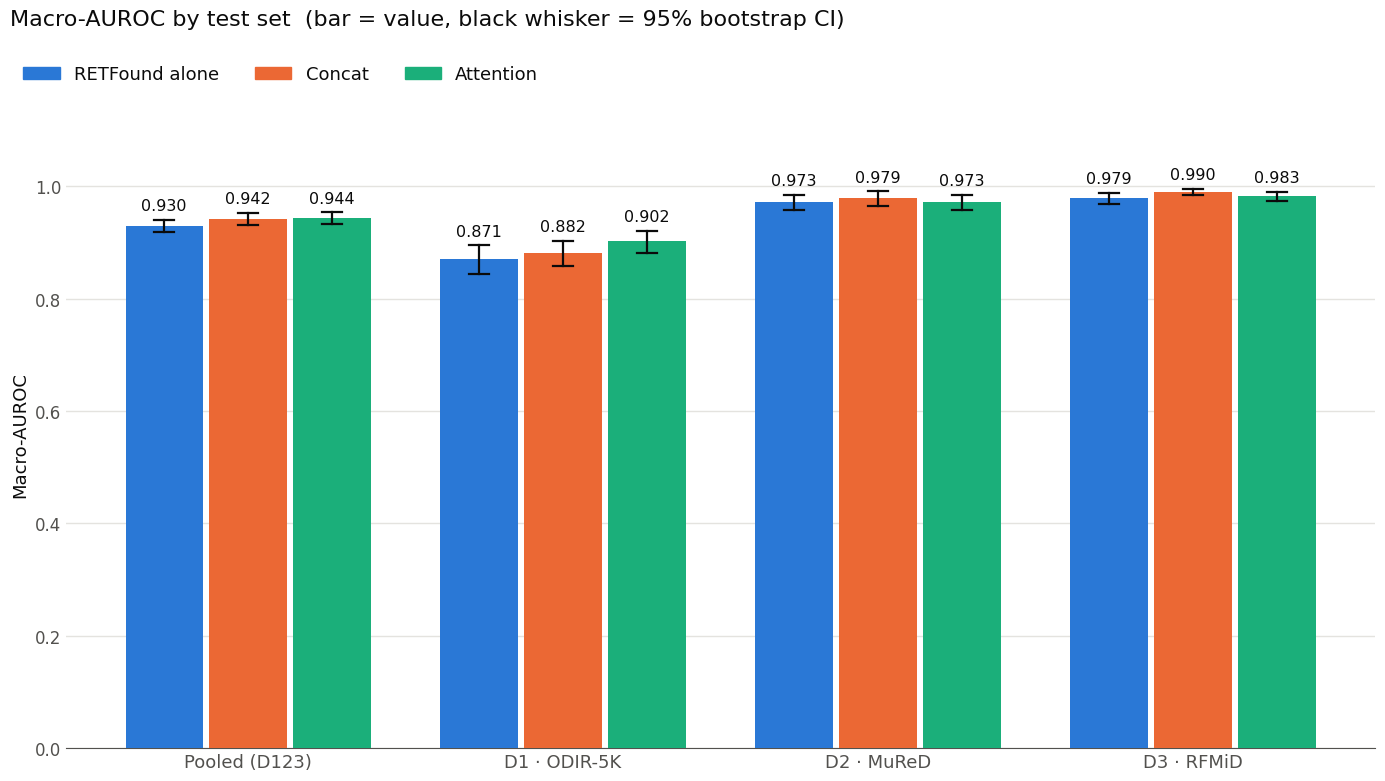

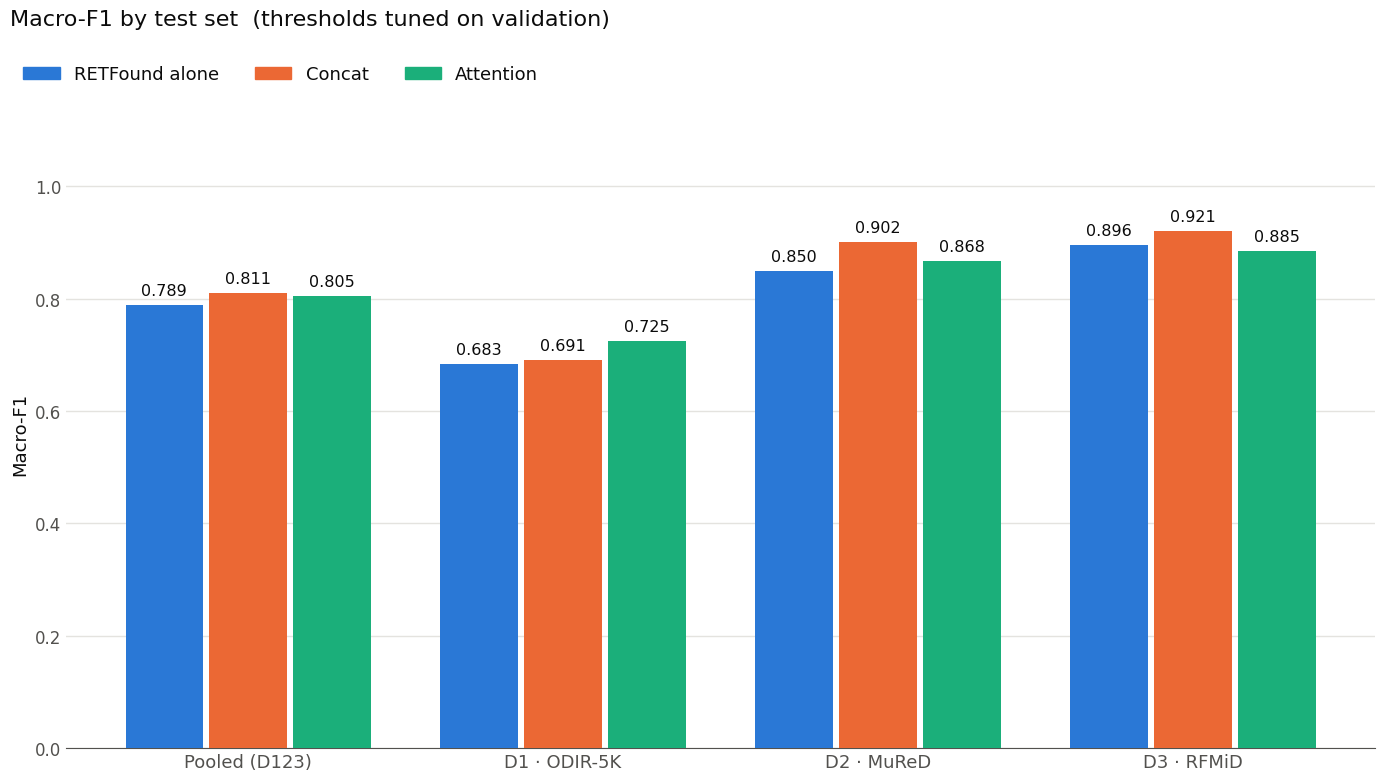

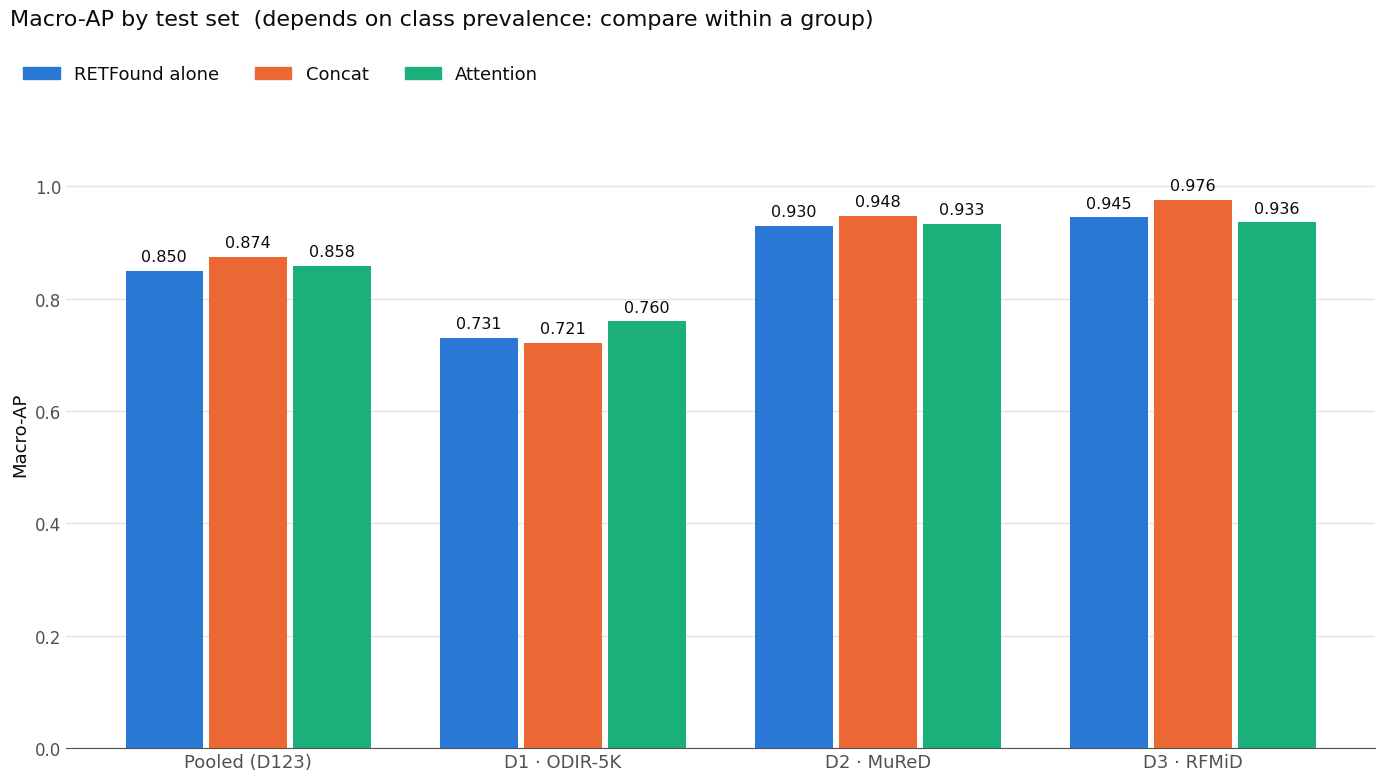

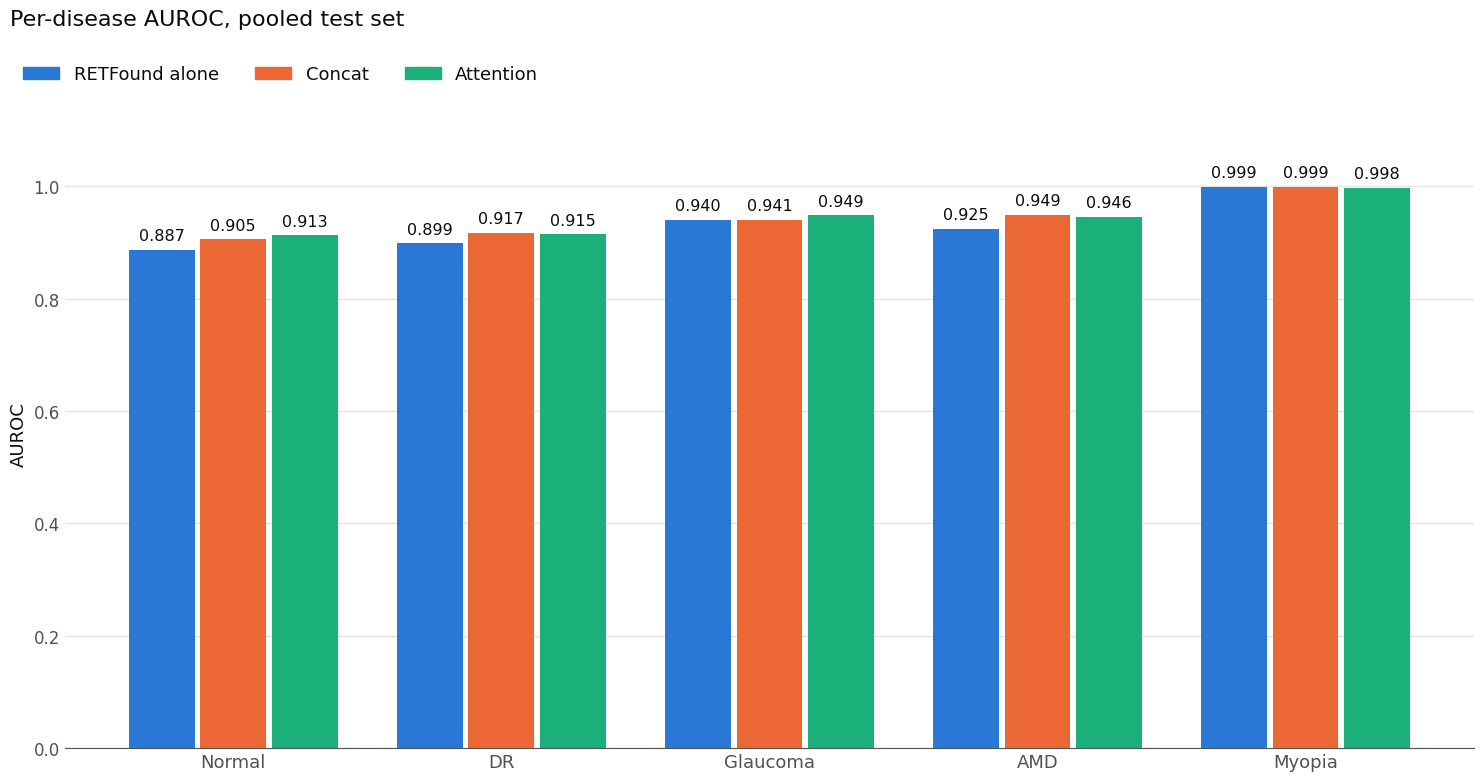

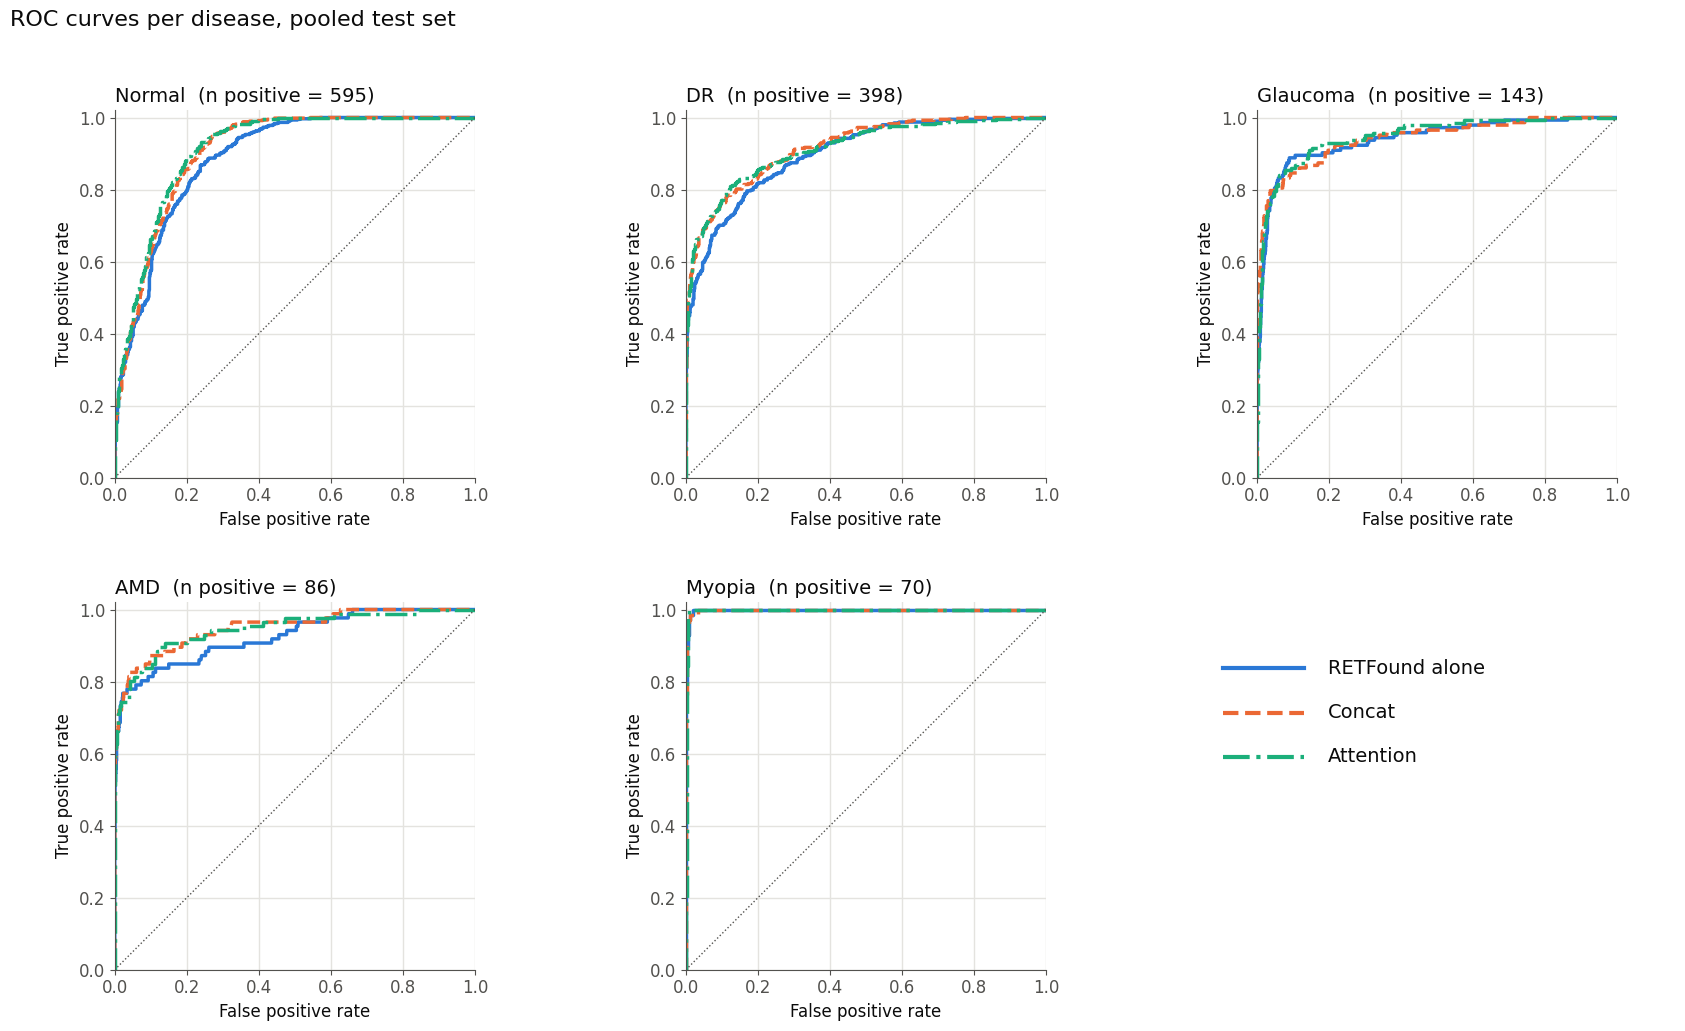

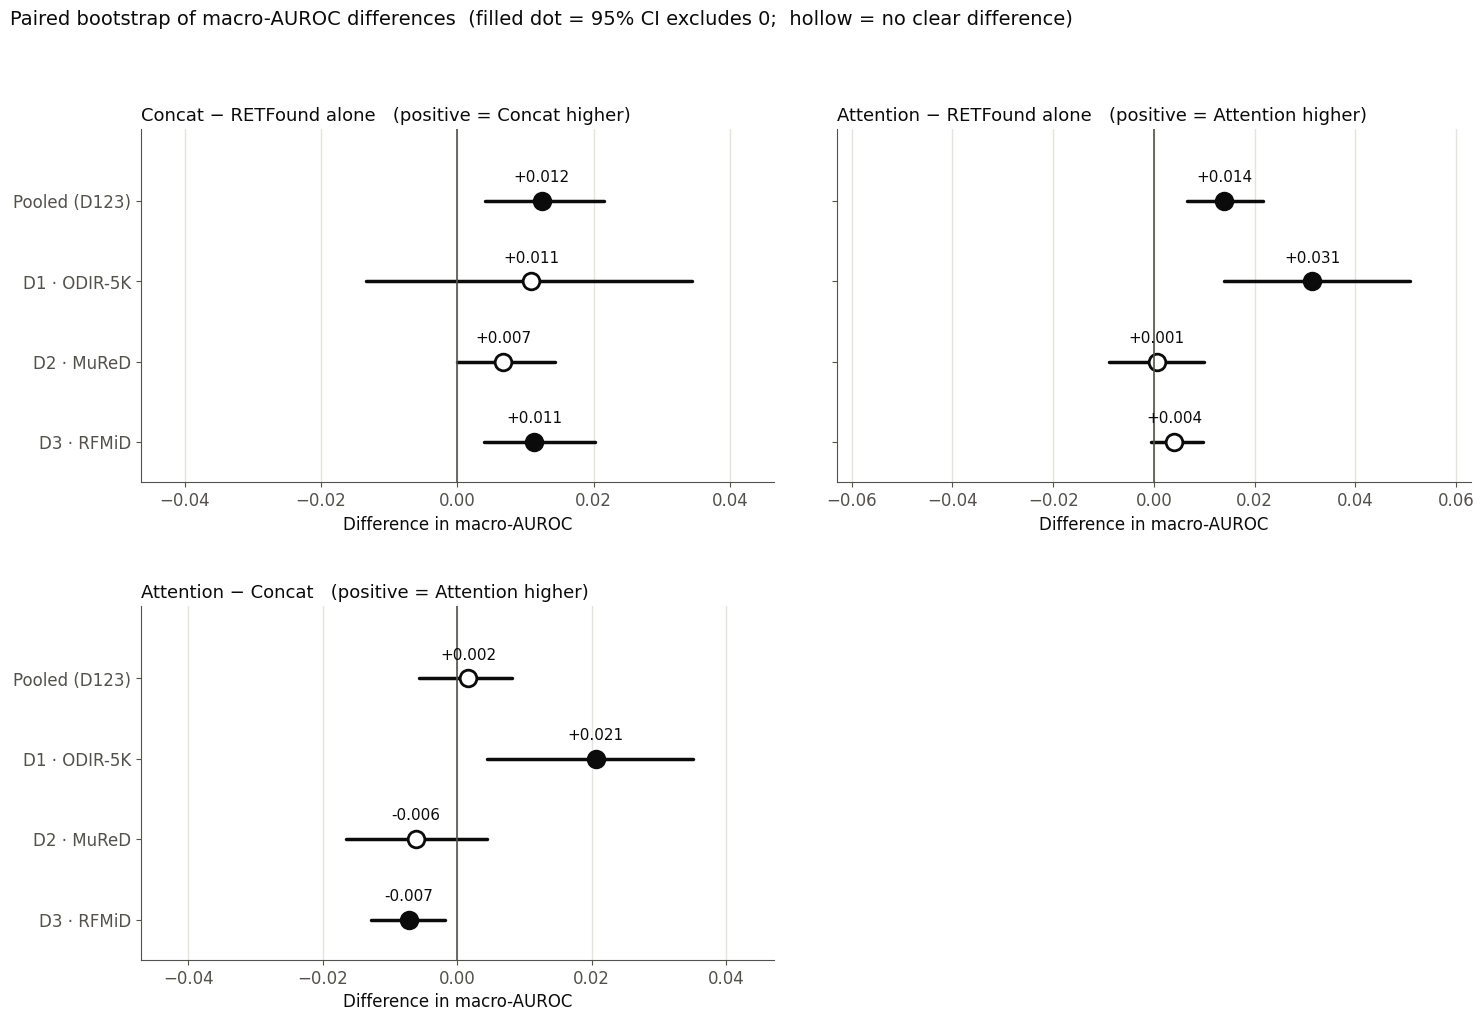


Saved to /kaggle/working/comparison_transformers : ['fig1_macro_auroc.png', 'fig2_macro_f1.png', 'fig3_macro_ap.png', 'fig4_per_class_auroc.png', 'fig5_roc_per_disease.png', 'fig6_paired_differences.png', 'table1_macro_by_set.csv', 'table2_per_class_pooled.csv', 'table3_paired_bootstrap.csv']


In [4]:
# ============================================================
# Comparison of 3 models within one group (baselines OR transformer-based)
# Each run folder must contain test_metrics.csv and test_predictions.csv
# ============================================================
import os, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

# ---------- EDIT ONLY THIS LINE ----------
GROUP = "transformers"          # run once with "baselines", then again with "transformers"
N_BOOT = 1000
# -----------------------------------------

def find_run(folder_name, root):
    """folder (exact name) that contains both result files"""
    for d, _, fs in os.walk(root):
        if os.path.basename(d) == folder_name and "test_predictions.csv" in fs and "test_metrics.csv" in fs:
            return d
    raise FileNotFoundError(f"No folder named '{folder_name}' with test_metrics.csv + test_predictions.csv under {root}. "
                            f"Add that notebook's output as an input (and make sure it was saved with Save & Run All).")

def find_run_kw(keyword, root):
    """any folder whose path contains the keyword and that holds both result files"""
    for d, _, fs in os.walk(root):
        if keyword in d.lower() and "test_predictions.csv" in fs and "test_metrics.csv" in fs:
            return d
    raise FileNotFoundError(f"No folder with '{keyword}' in its path and both result files under {root}. Upload the RETFound results as a dataset named retfound-d123-results and add it as input.")

ALL_RUNS = {
    "baselines": {
        "VGG16":           "/kaggle/working/baselines/VGG16",
        "ResNet50":        "/kaggle/working/baselines/ResNet50",
        "EfficientNet-B3": "/kaggle/working/baselines/EfficientNet-B3",
    },
    "transformers": {
        "RETFound alone":  lambda: find_run_kw("retfound", "/kaggle/input"),
        "Concat":          lambda: find_run("Fusion_D123", "/kaggle/input"),
        "Attention":       lambda: find_run("AttnFusion_D123", "/kaggle/input"),
    },
}
RUNS = {k: (v() if callable(v) else v) for k, v in ALL_RUNS[GROUP].items()}
print("run folders:", RUNS)
OUT = f"/kaggle/working/comparison_{GROUP}"

CLASSES = ["Normal", "DR", "Glaucoma", "AMD", "Myopia"]
SETS = ["D123_in_domain", "D1_test", "D2_test", "D3_test"]
LABEL = {"D123_in_domain": "Pooled (D123)", "D1_test": "D1 · ODIR-5K", "D2_test": "D2 · MuReD", "D3_test": "D3 · RFMiD"}
NAMES = list(RUNS)
COLOR = dict(zip(NAMES, ["#2a78d6", "#eb6834", "#1baf7a"]))   # validated, fixed per model
MARK = dict(zip(NAMES, ["o", "s", "^"]))
STYLE = dict(zip(NAMES, ["-", "--", "-."]))
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.facecolor": "white", "axes.facecolor": "white"})
try:
    from IPython.display import display
except Exception:
    display = print

# ---------- load + align on identical images
M, P = {}, {}
for n, d in RUNS.items():
    for f in ("test_metrics.csv", "test_predictions.csv"):
        assert os.path.exists(os.path.join(d, f)), f"missing {f} in {d} (model: {n})"
    M[n] = pd.read_csv(os.path.join(d, "test_metrics.csv"))
    P[n] = pd.read_csv(os.path.join(d, "test_predictions.csv"))

A = {}
for s in SETS:
    keys = None
    for n in NAMES:
        k = set(P[n].loc[P[n].test_set == s, "filename"])
        keys = k if keys is None else keys & k
    sizes = {n: int((P[n].test_set == s).sum()) for n in NAMES}
    if any(v != len(keys) for v in sizes.values()):
        print(f"WARNING {s}: models do not share the same images {sizes} -> using the {len(keys)} common ones")
    ref, probs = None, {}
    for n in NAMES:
        g = P[n][(P[n].test_set == s) & P[n].filename.isin(keys)].sort_values("filename").reset_index(drop=True)
        if ref is None:
            ref = g[CLASSES].values
        else:
            assert (g[CLASSES].values == ref).all(), f"labels differ between models in {s}"
        probs[n] = g[[f"prob_{c}" for c in CLASSES]].values
    A[s] = (ref, probs)


def macro_auc(Y, Pr):
    v = [roc_auc_score(Y[:, j], Pr[:, j]) for j in range(5) if 0 < Y[:, j].sum() < len(Y)]
    return np.mean(v) if len(v) == 5 else np.nan


# ---------- tables
rows = []
for n in NAMES:
    for s in SETS:
        r = M[n][(M[n].test_set == s) & (M[n]["class"] == "macro")].iloc[0]
        rows.append({"model": n, "test_set": s, "macro_AUROC": r.AUC, "macro_AP": r.AP, "macro_F1": r.F1})
T = pd.DataFrame(rows)
cols = [(k, LABEL[s]) for k in ["macro_AUROC", "macro_AP", "macro_F1"] for s in SETS]
tab = T.assign(test_set=T.test_set.map(LABEL)).pivot(index="model", columns="test_set",
        values=["macro_AUROC", "macro_AP", "macro_F1"]).reindex(NAMES).reindex(columns=cols)
print("\n=== TABLE 1: macro metrics by test set ===")
display(tab.round(4)); tab.round(4).to_csv(f"{OUT}/table1_macro_by_set.csv")

pc = []
for n in NAMES:
    for c in CLASSES:
        r = M[n][(M[n].test_set == "D123_in_domain") & (M[n]["class"] == c)].iloc[0]
        pc.append({"model": n, "class": c, "AUROC": r.AUC, "AP": r.AP, "F1": r.F1})
PC = pd.DataFrame(pc)
t2 = PC.pivot(index="class", columns="model", values=["AUROC", "AP", "F1"]).reindex(CLASSES)
t2 = t2.reindex(columns=[(k, n) for k in ["AUROC", "AP", "F1"] for n in NAMES])
print("\n=== TABLE 2: per-class metrics, pooled test set ===")
display(t2.round(4)); t2.round(4).to_csv(f"{OUT}/table2_per_class_pooled.csv")

# ---------- all pairs within the group
Yp, prp = A["D123_in_domain"]
PAIRS = [(b, a) for a, b in itertools.combinations(NAMES, 2)]   # (first, second): positive difference = first higher

# ---------- bootstrap, same resample for every model
rng = np.random.default_rng(42)
CI, DIFF = {}, {}
for s in SETS:
    Y, pr = A[s]; n_img = len(Y)
    boot = {n: [] for n in NAMES}
    for _ in range(N_BOOT):
        i = rng.integers(0, n_img, n_img)
        v = {n: macro_auc(Y[i], pr[n][i]) for n in NAMES}
        if not any(np.isnan(x) for x in v.values()):
            for n in NAMES:
                boot[n].append(v[n])
    for n in NAMES:
        CI[(s, n)] = (macro_auc(Y, pr[n]), *np.percentile(boot[n], [2.5, 97.5]))
    for a, b in PAIRS:
        d = np.array(boot[a]) - np.array(boot[b])
        DIFF[(s, a, b)] = (macro_auc(Y, pr[a]) - macro_auc(Y, pr[b]), *np.percentile(d, [2.5, 97.5]))
dt = pd.DataFrame([{"test_set": LABEL[s], "comparison": f"{a} - {b}", "AUROC_diff": v[0], "CI_low": v[1], "CI_high": v[2],
                    "clear difference (CI excludes 0)": not (v[1] <= 0 <= v[2])} for (s, a, b), v in DIFF.items()])
print("\n=== TABLE 3: paired bootstrap of macro-AUROC differences (95% CI) ===")
display(dt.round(4)); dt.round(4).to_csv(f"{OUT}/table3_paired_bootstrap.csv", index=False)


# ---------- figures
def style_ax(ax, axis="x"):
    ax.grid(axis=axis, color=GRID, linewidth=1); ax.set_axisbelow(True)


def head(fig, title, y=0.975):
    """title on top-left, legend directly below it (never overlapping)"""
    fig.text(0.012, y, title, fontsize=16, ha="left", va="top")
    hs = [plt.Rectangle((0, 0), 1, 1, color=COLOR[n], label=n) for n in NAMES]
    fig.legend(handles=hs, loc="upper left", ncol=len(NAMES), frameon=False, bbox_to_anchor=(0.01, y - 0.05), fontsize=13)


def grouped_bars(groups, group_labels, value, fname, title, ylabel, ci=None, figsize=(14, 8)):
    """bars start at ZERO (honest height). value(g, n) -> number; ci(g, n) -> (lo, hi) optional whiskers."""
    fig, ax = plt.subplots(figsize=figsize)
    w = 0.8 / len(NAMES)
    for k, n in enumerate(NAMES):
        for gi, g in enumerate(groups):
            x = gi + (k - (len(NAMES) - 1) / 2) * w
            v = value(g, n)
            ax.bar(x, v, width=w * 0.92, color=COLOR[n], zorder=3)
            top = v
            if ci is not None:
                lo, hi = ci(g, n)
                ax.plot([x, x], [lo, hi], color=INK, lw=1.6, zorder=4)
                for e in (lo, hi):
                    ax.plot([x - w * 0.12, x + w * 0.12], [e, e], color=INK, lw=1.6, zorder=4)
                top = hi
            ax.text(x, top + 0.012, f"{v:.3f}", ha="center", va="bottom", fontsize=11.5, color=INK, zorder=5)
    ax.set_xticks(range(len(groups))); ax.set_xticklabels(group_labels, fontsize=13)
    ax.set_ylim(0, 1.12); ax.set_yticks(np.arange(0, 1.01, 0.2)); ax.set_ylabel(ylabel, fontsize=13)
    ax.grid(axis="y", color=GRID, linewidth=1); ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0); ax.tick_params(axis="x", length=0)
    head(fig, title)
    fig.tight_layout(rect=(0, 0, 1, 0.86)); fig.savefig(f"{OUT}/{fname}", dpi=200); plt.show()


grouped_bars(SETS, [LABEL[s] for s in SETS], lambda g, n: CI[(g, n)][0], "fig1_macro_auroc.png",
             "Macro-AUROC by test set  (bar = value, black whisker = 95% bootstrap CI)", "Macro-AUROC",
             ci=lambda g, n: CI[(g, n)][1:])
grouped_bars(SETS, [LABEL[s] for s in SETS], lambda g, n: T[(T.model == n) & (T.test_set == g)]["macro_F1"].iloc[0],
             "fig2_macro_f1.png", "Macro-F1 by test set  (thresholds tuned on validation)", "Macro-F1")
grouped_bars(SETS, [LABEL[s] for s in SETS], lambda g, n: T[(T.model == n) & (T.test_set == g)]["macro_AP"].iloc[0],
             "fig3_macro_ap.png", "Macro-AP by test set  (depends on class prevalence: compare within a group)", "Macro-AP")
grouped_bars(CLASSES, CLASSES, lambda g, n: PC[(PC.model == n) & (PC["class"] == g)].AUROC.iloc[0],
             "fig4_per_class_auroc.png", "Per-disease AUROC, pooled test set", "AUROC", figsize=(15, 8))

ROC_MODELS = NAMES
fig, axs = plt.subplots(2, 3, figsize=(17, 10.5))
for j, c in enumerate(CLASSES):
    ax = axs.flat[j]
    for n in ROC_MODELS:
        fpr, tpr, _ = roc_curve(Yp[:, j], prp[n][:, j])
        ax.plot(fpr, tpr, STYLE[n], color=COLOR[n], lw=2.5)
    ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls=":")
    ax.set_title(f"{c}  (n positive = {int(Yp[:, j].sum())})", loc="left", fontsize=14)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.set_aspect("equal", adjustable="box"); style_ax(ax, "both")
ax = axs.flat[5]; ax.axis("off")
for k, n in enumerate(ROC_MODELS):
    ax.plot([0.05, 0.22], [0.82 - k * 0.12] * 2, STYLE[n], color=COLOR[n], lw=3)
    ax.text(0.27, 0.82 - k * 0.12, n, va="center", fontsize=14)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
fig.suptitle("ROC curves per disease, pooled test set", x=0.01, ha="left", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96), h_pad=3, w_pad=3); fig.savefig(f"{OUT}/fig5_roc_per_disease.png", dpi=170); plt.show()

# paired differences
ncol = 2; nrow = int(np.ceil(len(PAIRS) / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(7.5 * ncol, 5.2 * nrow), sharey=True, squeeze=False)
for ax, (a, b) in zip(axs.flat, PAIRS):
    for si, s in enumerate(SETS):
        v, lo, hi = DIFF[(s, a, b)]
        clear = not (lo <= 0 <= hi)
        ax.plot([lo, hi], [si, si], color=INK, lw=2.5, solid_capstyle="round")
        ax.plot(v, si, "o", ms=12, mec=INK, mew=2, mfc=INK if clear else "white")
        ax.text(v, si - 0.2, f"{v:+.3f}", va="bottom", ha="center", fontsize=11)
    ax.axvline(0, color=MUTED, lw=1.2)
    ax.set_title(f"{a} − {b}   (positive = {a} higher)", loc="left", fontsize=13)
    ax.set_xlabel("Difference in macro-AUROC"); style_ax(ax, "x")
    lim = max(abs(DIFF[(s, a, b)][k]) for s in SETS for k in (1, 2)) + 0.012
    ax.set_xlim(-lim, lim)
    ax.set_yticks(range(len(SETS))); ax.set_yticklabels([LABEL[s] for s in SETS], fontsize=12)
axs.flat[0].set_ylim(len(SETS) - 0.5, -0.9)   # shared y axis: set once; inverted so "Pooled" is on top, headroom for labels
for ax in list(axs.flat)[len(PAIRS):]:
    ax.axis("off")
fig.suptitle("Paired bootstrap of macro-AUROC differences  (filled dot = 95% CI excludes 0;  hollow = no clear difference)",
             x=0.01, ha="left", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.94), h_pad=3, w_pad=3); fig.savefig(f"{OUT}/fig6_paired_differences.png", dpi=200); plt.show()
print("\nSaved to", OUT, ":", sorted(os.listdir(OUT)))